# Neural Network Baseline

In this section, we train a baseline neural network on the text data, showcasing initial results from the evaluation plan at the end. Many of the findings from the baseline model will determine future approaches that are taken to improve the model. 

As a first step, the data is loaded, duplicates are dropped, and the labels are extracted.

In [2]:
import pandas as pd
from pathlib import Path

data_path = Path("data/clean_data.csv")

df = pd.read_csv(data_path)

df = df.drop_duplicates(subset=['Description', 'Type']) # Drop duplicates between text and label
df = df.drop_duplicates(subset=['Description'], keep=False) # Drop duplicate text with different labels

texts = df["Description"].values # Features
labels = df["Type"].values # Targets

print(df["Type"].value_counts())

Type
Grievance             6482
Required Support      2192
Enquiry               1186
Complaint              547
Suggestion              82
Willing to Support      20
Appreciation            10
Name: count, dtype: int64


Some classes are rarer than others, which needs to be accounted for in the train/test split.

# 1. Encode Target Labels

All of the target label sentiments need to be encoded as integers in order to be predicted by the neural network.

In [3]:
from sklearn.preprocessing import LabelEncoder

encoder = LabelEncoder()
y = encoder.fit_transform(labels)

# Print the new encoded labels
print(y)

[2 3 4 ... 1 5 3]


# 2. Data Splits

The data is split according to the evaluation plan. First, a 85/15 train/test split and then, a train/validation split. The split of the data is stratified to try to keep the proportions the same across datasets for the rarer classes.

In [4]:
from sklearn.model_selection import train_test_split

# Train/Test split
x_train, x_test, y_train, y_test = train_test_split(
    texts, y,
    test_size=0.15,
    stratify=y,
    random_state=42
)

# Train/Validation split
x_train, x_val, y_train, y_val = train_test_split(
    x_train, y_train,
    test_size=0.15,
    stratify=y_train,
    random_state=42
)

print(f"Number of observations in training set: " + str(len(x_train)))
print(f"Number of observations in validation set: " + str(len(x_val)))
print(f"Number of observations in test set: " + str(len(x_test)))

Number of observations in training set: 7599
Number of observations in validation set: 1342
Number of observations in test set: 1578


# 3. Building The Vocabulary

Before building our full vocabulary, we need to tokenize the text into words by splitting on whitespace and getting rid of all punctuation.

In [5]:
from collections import Counter
import re

def tokenize(text): # Tokenize based on whitespace
    text = text.lower()
    text = re.sub(r"[^\w\s]", "", text)
    return text.split()

token_counts = Counter()
for text in x_train:
    token_counts.update(tokenize(text))

train_vocab = ["<pad>", "<unk>"] + [word for word, count in token_counts.most_common()]

word2idx = {word: idx for idx, word in enumerate(train_vocab)}

print("Full vocabulary size:", len(train_vocab))

Full vocabulary size: 14449


The total vocabulary size of the training set isn't very big so we'll keep the full vocabulary. However, we may explore capping the maximum tokens later on.

A CNN needs each observation to be the same length so the training set forms a rectangle. In order to decide the length, we need to find the max length of the observations first, decide on a sequence length, and then pad the rest of the observations.

In [6]:
import numpy as np

lengths = [len(tokenize(t)) for t in x_train]

print("Mean observation length: " + str(np.mean(lengths)))
print("Longest observation length: " + str(np.max(lengths)))

Mean observation length: 60.269640742202924
Longest observation length: 178


For the baseline model, we will use 178 as the sequence length since it is the longest observation in the training set. However, we will explore capping the sequence length in the future. Now, we need to count the tokens in the training set to see if we need to cap the number.

In [7]:
SEQ_LEN = np.max(lengths) # Sequence length: set with the longest observation
PAD = 0
UNK = 1

def encode(text):
    ids = [word2idx.get(word, UNK) for word in tokenize(text)]
    ids = ids[:SEQ_LEN] # Gets shortened if its too long
    ids = ids + [PAD] * (SEQ_LEN - len(ids)) # Pads if its too short
    return ids

Now that the vocabulary has been built from the training set, we can apply the same vectorizer to all three of the data sets.

In [8]:
import torch

# Apply the vectorizer to the three data sets
x_train_vec = torch.tensor([encode(t) for t in x_train], dtype=torch.long)
x_val_vec = torch.tensor([encode(t) for t in x_val], dtype=torch.long)
x_test_vec = torch.tensor([encode(t) for t in x_test], dtype=torch.long)

print(x_train_vec.shape) # Make sure that the new training set shape is correct

torch.Size([7599, 178])


# 4. Build The CNN Model

Now we will construct the baseline structure of the Convolutional Neural Network that will be used to take in the text to predict the sentiment label. The structure is defined first including key hyperparameters before any training can occur. 

In [9]:
import torch.nn as nn

VOCAB_SIZE = len(train_vocab) # Set vocab size
EMBED_DIM = 64 # Embedding dimensions
NUM_CLASSES = 7

class BaselineCNN(nn.Module):
    def __init__(self, vocab_size, embed_dim, num_classes):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embed_dim, padding_idx=0) # Embed first
        self.conv = nn.Conv1d(in_channels=embed_dim, out_channels=64, kernel_size=5) # Keep kernel size reasonable
        self.fc = nn.Linear(64, num_classes) # Linear layer

    def forward(self, x):
        x = self.embedding(x)
        x = x.permute(0, 2, 1)
        x = torch.relu(self.conv(x)) # Activation
        x = x.max(dim=2).values # Global max pooling
        return self.fc(x)

model = BaselineCNN(VOCAB_SIZE, EMBED_DIM, NUM_CLASSES) # Create object of class
print(model)

BaselineCNN(
  (embedding): Embedding(14449, 64, padding_idx=0)
  (conv): Conv1d(64, 64, kernel_size=(5,), stride=(1,))
  (fc): Linear(in_features=64, out_features=7, bias=True)
)


The model is set up to be a baseline with the following key hyperparameters:
* embed_dim: 64. This is a good starting place as it has fewer parameters and the dataset is smaller.
* out_channels: 64. This is a good starting place for one kernel size and a smaller dataset.
* kernel_size: 5. The model will look at five words at a time, which is a good starting place to cover shorter descriptions.
* activation: ReLU. This is the most commonly used activation function in deep learning.
* layers: one convolution layer and one linear output layer. This is a simple setup that we will later look to enhance with dropout.

# 5. Training The Model

Since the model structure is defined, we are ready to start the training loop. The evaluation function is defined first at the top as well as the loss. Then, the training loop is shown over 50 epochs (or until early stopping occurs) with validation metrics.

In [10]:
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score

criterion = nn.CrossEntropyLoss() # Loss metric

def evaluate(model, loader):
    model.eval() # Needed during eval stage
    all_preds, all_labels = [], []
    total_loss = 0

    with torch.no_grad():
        for xb, yb in loader:
            logits = model(xb)
            total_loss += criterion(logits, yb).item() * len(yb)
            all_preds.extend(logits.argmax(dim=1).tolist())
            all_labels.extend(yb.tolist())

    return {
        "loss": total_loss / len(all_labels),
        "accuracy": accuracy_score(all_labels, all_preds),
        "f1": f1_score(all_labels, all_preds, average="macro", zero_division=0),
        "precision": precision_score(all_labels, all_preds, average="macro", zero_division=0),
        "recall": recall_score(all_labels, all_preds, average="macro", zero_division=0),
    }

Loss: nn.CrossEntropyLoss() was picked because this is multi-class classification with integers numbered 0-6.

In [11]:
from torch.utils.data import TensorDataset, DataLoader

y_train_t = torch.tensor(y_train, dtype=torch.long)
y_val_t   = torch.tensor(y_val, dtype=torch.long)
y_test_t  = torch.tensor(y_test, dtype=torch.long)

train_ds = TensorDataset(x_train_vec, y_train_t)
val_ds = TensorDataset(x_val_vec, y_val_t)
test_ds = TensorDataset(x_test_vec, y_test_t)

train_loader = DataLoader(train_ds, batch_size=32, shuffle=True)
val_loader   = DataLoader(val_ds, batch_size=32)
test_loader  = DataLoader(test_ds, batch_size=32)

Optimizer: "adam" was picked instead of "adamw" for the baseline model. Later on, we'll switch to adamw to add weight decay as a comparison to this model.

In [12]:
torch.manual_seed(42)   # Reproduce weight initialization and shuffling

model = BaselineCNN(VOCAB_SIZE, EMBED_DIM, NUM_CLASSES) # Initialize weights
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3) # Model optimizer

EPOCHS = 50 # Set max epochs
PATIENCE = 15 # Set patience

hist = []
best_loss, best_epoch, best_weights, waited = float("inf"), -1, None, 0

for epoch in range(1, EPOCHS+1):
    # Training loop
    model.train()
    train_loss = 0.0

    for xb, yb in train_loader:
        optimizer.zero_grad()
        logits = model(xb)
        loss = criterion(logits, yb)
        loss.backward()
        optimizer.step()
        train_loss += loss.item() * len(yb)

    train_loss /= len(train_ds)

    # Metrics on validation set
    val_metrics = evaluate(model, val_loader)
    hist.append({"epoch": epoch, "train_loss": train_loss, **{f"val_{k}": v for k, v in val_metrics.items()}})

    print(f"Epoch {epoch:2d} | train_loss {train_loss:.4f} | "
          f"val_loss {val_metrics['loss']:.4f} | val_acc {val_metrics['accuracy']:.4f} | "
          f"val_f1 {val_metrics['f1']:.4f}")

    # Configure Early stopping
    if val_metrics["loss"] < best_loss:
        best_loss = val_metrics["loss"]
        best_weights = {k: v.clone() for k, v in model.state_dict().items()}
        waited = 0
        best_epoch = epoch
    else:
        waited += 1
        if waited >= PATIENCE:
            print(f"Early stopping at epoch {epoch}")
            break

model.load_state_dict(best_weights) # Restore the best weights

print(f"Ran {len(hist)} epochs, kept epoch {best_epoch}")
print(f"Validation loss at the epoch we kept : {best_loss}")

Epoch  1 | train_loss 1.1144 | val_loss 1.0864 | val_acc 0.6073 | val_f1 0.1461
Epoch  2 | train_loss 0.9659 | val_loss 1.0507 | val_acc 0.6006 | val_f1 0.1610
Epoch  3 | train_loss 0.8638 | val_loss 1.0648 | val_acc 0.5969 | val_f1 0.1527
Epoch  4 | train_loss 0.7496 | val_loss 1.0679 | val_acc 0.6110 | val_f1 0.1615
Epoch  5 | train_loss 0.6126 | val_loss 1.0974 | val_acc 0.5790 | val_f1 0.1878
Epoch  6 | train_loss 0.4710 | val_loss 1.1523 | val_acc 0.5872 | val_f1 0.1868
Epoch  7 | train_loss 0.3504 | val_loss 1.2158 | val_acc 0.5566 | val_f1 0.1978
Epoch  8 | train_loss 0.2493 | val_loss 1.3001 | val_acc 0.5641 | val_f1 0.1944
Epoch  9 | train_loss 0.1723 | val_loss 1.3653 | val_acc 0.5708 | val_f1 0.1863
Epoch 10 | train_loss 0.1213 | val_loss 1.4459 | val_acc 0.5350 | val_f1 0.1913
Epoch 11 | train_loss 0.0838 | val_loss 1.5104 | val_acc 0.5730 | val_f1 0.1889
Epoch 12 | train_loss 0.0639 | val_loss 1.5869 | val_acc 0.5626 | val_f1 0.1845
Epoch 13 | train_loss 0.0495 | val_loss 

The baseline model overfits immediately since validation loss is minimized at epoch 2 and increases after while training loss goes down. At epoch 2, validation accuracy is at 60.06%, slightly below the majority class baseline of 61.6%. The macro F1 does indicate with a value of 0.1610, however, that the model does capture some other classes beyond the majority class.

# 6. Test Set Results


### Baseline CNN Test Performance

After training the CNN and selecting the best model using validation loss, we evaluate its performance on the held-out test set to see how well the model generalizes to unseen text.

We report test loss, accuracy, macro precision, macro recall, and macro F1-score. Since the dataset is somehow imbalanced, macro-averaged metrics are important because they give equal weight to each class.


In [13]:

# Section 6: Test Set Results
# Evaluate the trained CNN on the unseen test data

test_metrics = evaluate(model, test_loader)

print("BASELINE CNN - TEST SET RESULTS")
print("-" * 40)
print(f"Test Loss:      {test_metrics['loss']:.4f}")
print(f"Test Accuracy:  {test_metrics['accuracy']:.4f}")
print(f"Test Precision: {test_metrics['precision']:.4f}")
print(f"Test Recall:    {test_metrics['recall']:.4f}")
print(f"Test Macro F1:  {test_metrics['f1']:.4f}")


BASELINE CNN - TEST SET RESULTS
----------------------------------------
Test Loss:      1.0554
Test Accuracy:  0.6096
Test Precision: 0.2139
Test Recall:    0.1730
Test Macro F1:  0.1692



The baseline CNN achieved a test accuracy of 60.96%, but its macro F1-score was only 0.1692. The model correctly classifies a majority of observations, its performance is uneven across the seven classes.

The low macro precision (0.2139) and recall (0.1730) show that the model struggles to identify several categories, particularly given the severe class imbalance in the dataset.

The training results also show signs of overfitting, as validation loss increased after epoch 2 while training loss continued to decrease.

These findings highlight the limitations of the baseline CNN and motivate further analysis of class-level performance.


# 7. Evaluation


### 7.1 Classification Report

To understand the baseline CNN's performance, we examine precision, recall, and F1-score for each class on the test set. Since the dataset is highly imbalanced, overall accuracy may hide poor performance on minority classes. The classification report helps identify which categories the model predicts well and which ones it struggles to recognize.


In [14]:

# give predictions on the held-out test set
from sklearn.metrics import classification_report
import torch

model.eval()

all_preds = []
all_labels = []

with torch.no_grad():
    for xb, yb in test_loader:
        logits = model(xb)
        predictions = torch.argmax(logits, dim=1)

        all_preds.extend(predictions.cpu().tolist())
        all_labels.extend(yb.cpu().tolist())

# Get the original class names
class_names = encoder.classes_

# Generate the classification report
print("BASELINE CNN - CLASSIFICATION REPORT")
print("-" * 55)

print(
    classification_report(
        all_labels,
        all_preds,
        labels=list(range(len(class_names))),
        target_names=class_names,
        digits=4,
        zero_division=0
    )
)


BASELINE CNN - CLASSIFICATION REPORT
-------------------------------------------------------
                    precision    recall  f1-score   support

      Appreciation     0.0000    0.0000    0.0000         2
         Complaint     0.0000    0.0000    0.0000        82
           Enquiry     0.5833    0.1966    0.2941       178
         Grievance     0.6362    0.9228    0.7531       972
  Required Support     0.2778    0.0912    0.1373       329
        Suggestion     0.0000    0.0000    0.0000        12
Willing to Support     0.0000    0.0000    0.0000         3

          accuracy                         0.6096      1578
         macro avg     0.2139    0.1730    0.1692      1578
      weighted avg     0.5156    0.6096    0.5257      1578



Grievance performs best, with an F1-score of 0.7531 and recall of 0.9228. However, Enquiry (0.2941) and Required Support (0.1373) show considerably weaker F1-scores.
4 categories—Appreciation, Complaint, Suggestion, and Willing to Support—have F1-scores of 0, indicating that the model failed to correctly classify any test observations from these categories.

These results suggest that the CNN is heavily influenced by the majority class. Although overall accuracy is approximately 61%, the macro F1-score of 0.1692 highlights poor performance across classes. It shows why accuracy alone is insufficient for evaluating this imbalanced dataset.



### 7.2 Confusion Matrix

To further investigate classification errors, we visualize the confusion matrix for the test set. The matrix compares the actual labels with the model's predicted labels. We will identify which categories are frequently misclassified and whether the model tends to predict the majority class instead of less common categories.


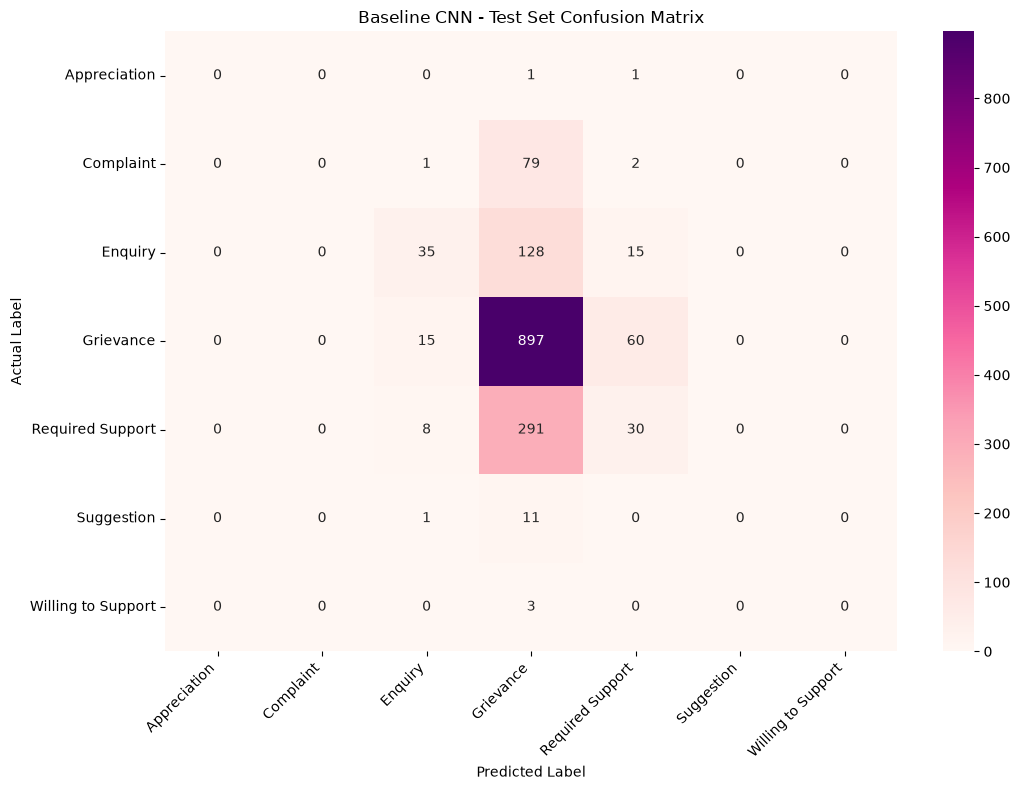

In [20]:

# Plot the confusion matrix for the baseline CNN
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(
    all_labels,
    all_preds,
    labels=list(range(len(class_names)))
)

plt.figure(figsize=(11, 8))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="RdPu",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.title("Baseline CNN - Test Set Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()


The confusion matrix shows that the baseline CNN strongly favors the Grievance category, which is the largest class in the dataset.

The model classified 897 Grievance observations but frequently misclassified other categories as Grievance. For example, 291 Required Support observations, 128 Enquiry observations, and 79 Complaint observations were incorrectly predicted as Grievance. The model also never predicted Appreciation, Complaint, Suggestion, or Willing to Support, demonstrating its difficulty recognizing minority classes. Class imbalance significantly affects the baseline CNN's performance. Although the model achieves approximately 61% accuracy, it struggles to distinguish between several categories.



### 7.3 Majority-Class Baseline Comparison

To determine whether the CNN performs better than a simple prediction strategy, we compare it against a majority-class baseline. This baseline always predicts Grievance, the most frequent category in the training dataset, regardless of the input text. We compare accuracy and macro F1-score to evaluate whether the CNN provides meaningful improvements over this simple approach.


In [21]:

# Compare the CNN with a majority-class baseline
import numpy as np
import pandas as pd
from sklearn.metrics import accuracy_score, f1_score

# Identify the majority class using training labels only
majority_class = np.bincount(y_train).argmax()

# Predict the majority class for every test observation
majority_preds = np.full(
    len(all_labels),
    majority_class
)

# Calculate baseline metrics
majority_accuracy = accuracy_score(all_labels, majority_preds)
majority_f1 = f1_score(
    all_labels,
    majority_preds,
    average="macro",
    labels=list(range(len(class_names))),
    zero_division=0
)

# Compare both models
comparison = pd.DataFrame({
    "Model": ["Majority-Class Baseline", "Baseline CNN"],
    "Accuracy": [majority_accuracy, test_metrics["accuracy"]],
    "Macro F1": [majority_f1, test_metrics["f1"]]
})

print("MODEL PERFORMANCE COMPARISON")
print("-" * 50)
print(comparison.to_string(index=False, float_format="%.4f"))


MODEL PERFORMANCE COMPARISON
--------------------------------------------------
                  Model  Accuracy  Macro F1
Majority-Class Baseline    0.6160    0.1089
           Baseline CNN    0.6096    0.1692


# 8. Conclusion



The baseline CNN was successfully trained and evaluated for seven-class text classification. The model achieved 60.96% test accuracy and a macro F1-score of 0.1692.

The evaluation revealed that the model performs best on the majority class, Grievance, while struggling with minority categories. Four classes received an F1-score of zero, highlighting the impact of class imbalance. The training results also showed signs of overfitting after epoch 2.

Although the CNN achieved slightly lower accuracy than the majority-class baseline (61.60%), its higher macro F1-score suggests that it learned some useful patterns beyond predicting the dominant class.

Future improvements will focus on addressing class imbalance through class-weighted loss, exploring dropout to reduce overfitting, and adjusting the CNN architecture to improve generalization.
